<img
  src="https://raw.githubusercontent.com/k-git-uconn/OPIM-5604-PredictiveModeling/main/5604_AssignmentImage.bmp"
  width="40%"
  alt="OPIM 5641 assignment banner"
/>

**Submitted Date: 11-11-2026**

# Environment Setup

In [27]:
# import modules

import pandas as pd # for data viz and wrangling
import numpy as np # for 'numeric python'
import matplotlib.pyplot as plt # for data viz (more complex than pylab)
import seaborn as sns
from pylab import * # for data viz (import * means 'import all of the functions')

from sklearn.feature_selection import SequentialFeatureSelector
from sklearn.metrics import mean_squared_error, r2_score, accuracy_score, classification_report, confusion_matrix, roc_curve, auc
from sklearn import metrics
from scipy import stats
import statsmodels.api as sm


# @1. Read in the Telco dataset and determine how many rows and columns it has.

In [31]:
# read data
# on the lefthand side, navigate to your data and copy the path
data_file = 'https://raw.githubusercontent.com/k-git-uconn/OPIM-5604-PredictiveModeling/main/M9/M9Assignment/Telco_customer_churn.csv'

df = pd.read_csv(data_file)

print("Number of rows:", df.shape[0])
print("Number of columns:", df.shape[1])

df.head()

Number of rows: 7043
Number of columns: 18


,CustomerID,Gender,Senior Citizen,Partner,Dependents,Tenure Months,Multiple Lines,Internet Service,Online Security,Online Backup,Device Protection,Tech Support,Contract,Paperless Billing,Electronic Check,Monthly Charges,Churn Label,Churn Value
0,3668-QPYBK,Male,No,No,No,2,No,DSL,Yes,Yes,No,No,Month-to-month,Yes,No,53.85,Yes,1
1,9237-HQITU,Female,No,No,Yes,2,No,Fiber optic,No,No,No,No,Month-to-month,Yes,Yes,70.70,Yes,1
2,9305-CDSKC,Female,No,No,Yes,8,Yes,Fiber optic,No,No,Yes,No,Month-to-month,Yes,Yes,99.65,Yes,1
3,7892-POOKP,Female,No,Yes,Yes,28,Yes,Fiber optic,No,No,Yes,Yes,Month-to-month,Yes,Yes,104.80,Yes,1
4,0280-XJGEX,Male,No,No,Yes,49,Yes,Fiber optic,No,Yes,Yes,No,Month-to-month,Yes,No,103.70,Yes,1


Number of rows: 7043


Number of columns: 18

In [32]:
# Preview
print(df.head())

   CustomerID  Gender Senior Citizen Partner Dependents  Tenure Months  \
0  3668-QPYBK    Male             No      No         No              2   
1  9237-HQITU  Female             No      No        Yes              2   
2  9305-CDSKC  Female             No      No        Yes              8   
3  7892-POOKP  Female             No     Yes        Yes             28   
4  0280-XJGEX    Male             No      No        Yes             49   

  Multiple Lines Internet Service Online Security Online Backup  \
0             No              DSL             Yes           Yes   
1             No      Fiber optic              No            No   
2            Yes      Fiber optic              No            No   
3            Yes      Fiber optic              No            No   
4            Yes      Fiber optic              No           Yes   

  Device Protection Tech Support        Contract Paperless Billing  \
0                No           No  Month-to-month               Yes   
1           

In [33]:
# list the columns with the data types
print(df.info())

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 7043 entries, 0 to 7042
Data columns (total 18 columns):
 #   Column             Non-Null Count  Dtype  
---  ------             --------------  -----  
 0   CustomerID         7043 non-null   object 
 1   Gender             7043 non-null   object 
 2   Senior Citizen     7043 non-null   object 
 3   Partner            7043 non-null   object 
 4   Dependents         7043 non-null   object 
 5   Tenure Months      7043 non-null   int64  
 6   Multiple Lines     7043 non-null   object 
 7   Internet Service   7043 non-null   object 
 8   Online Security    7043 non-null   object 
 9   Online Backup      7043 non-null   object 
 10  Device Protection  7043 non-null   object 
 11  Tech Support       7043 non-null   object 
 12  Contract           7043 non-null   object 
 13  Paperless Billing  7043 non-null   object 
 14  Electronic Check   7043 non-null   object 
 15  Monthly Charges    7043 non-null   float64
 16  Churn Label        7043 

Looks like a mix of categorical and continuous predictors.  We should  change data type of  variable and value to 1s and 0s.  Also let's make dummy variables.

In [34]:
# Separate target variable
target = df['Churn Value']

# Remove unnecessary columns and target
features = df.drop(columns=['CustomerID', 'Churn Label', 'Churn Value'])

# Identify categorical variables
categorical_cols = features.select_dtypes(include=['object']).columns

# Create dummy variables
features = pd.get_dummies(
    features,
    columns=categorical_cols,
    drop_first=True,
    dtype=int
)

In [35]:
# Check missing values
print(features.isnull().sum().sum())

# Check target distribution
print(target.value_counts())

0
Churn Value
0    5174
1    1869
Name: count, dtype: int64


In [36]:
# Check the final values before partition
print(features.head())
print(features.shape)

   Tenure Months  Monthly Charges  Gender_Male  Senior Citizen_Yes  \
0              2            53.85            1                   0   
1              2            70.70            0                   0   
2              8            99.65            0                   0   
3             28           104.80            0                   0   
4             49           103.70            1                   0   

   Partner_Yes  Dependents_Yes  Multiple Lines_No phone service  \
0            0               0                                0   
1            0               1                                0   
2            0               1                                0   
3            1               1                                0   
4            0               1                                0   

   Multiple Lines_Yes  Internet Service_Fiber optic  Internet Service_No  \
0                   0                             0                    0   
1                   0   

# @2. Partition the data into a 60/20/20 split.

In [37]:
from sklearn.model_selection import train_test_split

# Define the target variable
target_variable = target

# Step 1: Split data into 60% training and 40% remaining
X_train, X_test, y_train, y_test = train_test_split(features, target_variable, test_size=0.4, random_state=42)

# Step 2: Split the remaining 40% equally into validation and test (20% each)
#X_train, X_val, y_train, y_val = train_test_split(X_train, y_train, test_size=0.5, random_state=42)

X_val, X_test, y_val, y_test = train_test_split(X_test, y_test, test_size=0.5, random_state=42)

# Print the shapes of the resulting datasets
print("Training set shape:", X_train.shape, y_train.shape)
print("Validation set shape:", X_val.shape, y_val.shape)
print("Test set shape:", X_test.shape, y_test.shape)

Training set shape: (4225, 18) (4225,)
Validation set shape: (1409, 18) (1409,)
Test set shape: (1409, 18) (1409,)


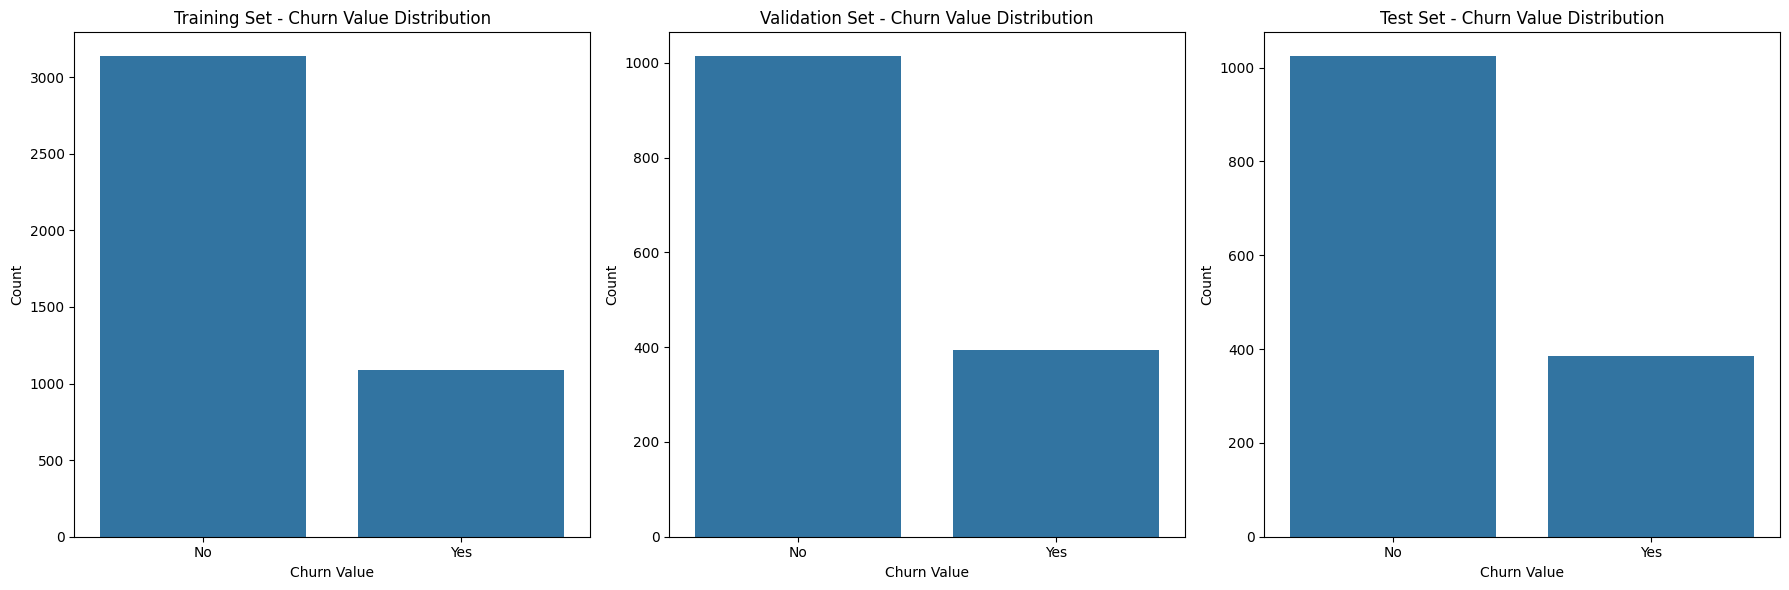

Training set Churn Value counts and percentages:
Churn Value
0    3136
1    1089
Name: count, dtype: int64
Churn Value
0    74.22
1    25.78
Name: proportion, dtype: float64

Validation set Churn Value counts and percentages:
Churn Value
0    1014
1     395
Name: count, dtype: int64
Churn Value
0    71.97
1    28.03
Name: proportion, dtype: float64

Test set Churn Value counts and percentages:
Churn Value
0    1024
1     385
Name: count, dtype: int64
Churn Value
0    72.68
1    27.32
Name: proportion, dtype: float64


In [38]:
import matplotlib.pyplot as plt
import seaborn as sns

# Combine the features and target for plotting
train_data = X_train.copy()
train_data['Churn Value'] = y_train

val_data = X_val.copy()
val_data['Churn Value'] = y_val

test_data = X_test.copy()
test_data['Churn Value'] = y_test

# Plot the distribution of 'Personal Loan' in each partition
fig, axs = plt.subplots(1, 3, figsize=(18, 6))

sns.countplot(data=train_data, x='Churn Value', ax=axs[0])
axs[0].set_title('Training Set - Churn Value Distribution')
axs[0].set_xlabel('Churn Value')
axs[0].set_ylabel('Count')
axs[0].set_xticks([0, 1])
axs[0].set_xticklabels(['No', 'Yes'])

sns.countplot(data=val_data, x='Churn Value', ax=axs[1])
axs[1].set_title('Validation Set - Churn Value Distribution')
axs[1].set_xlabel('Churn Value')
axs[1].set_ylabel('Count')
axs[1].set_xticks([0, 1])
axs[1].set_xticklabels(['No', 'Yes'])


sns.countplot(data=test_data, x='Churn Value', ax=axs[2])
axs[2].set_title('Test Set - Churn Value Distribution')
axs[2].set_xlabel('Churn Value')
axs[2].set_ylabel('Count')
axs[2].set_xticks([0, 1])
axs[2].set_xticklabels(['No', 'Yes'])

plt.tight_layout()
plt.show()

# Print counts and percentages for each partition
print("Training set Churn Value counts and percentages:")
train_counts = train_data['Churn Value'].value_counts()
train_percentages = train_data['Churn Value'].value_counts(normalize=True) * 100
print(train_counts)
print(train_percentages.round(2)) # Round percentages to 2 decimal places


print("\nValidation set Churn Value counts and percentages:")
val_counts = val_data['Churn Value'].value_counts()
val_percentages = val_data['Churn Value'].value_counts(normalize=True) * 100
print(val_counts)
print(val_percentages.round(2)) # Round percentages to 2 decimal places


print("\nTest set Churn Value counts and percentages:")
test_counts = test_data['Churn Value'].value_counts()
test_percentages = test_data['Churn Value'].value_counts(normalize=True) * 100
print(test_counts)
print(test_percentages.round(2)) # Round percentages to 2 decimal places

Approximately 72–74% of customers did not churn.



Approximately 26–28% of customers churned.



The distributions are reasonably consistent, although there is some variation.

# @3. Build a discriminant analysis model to predict churn using all predictors.

First we fit the model.

In [39]:
from sklearn.discriminant_analysis import LinearDiscriminantAnalysis

# Initialize the LDA model
lda_model = LinearDiscriminantAnalysis()

# Train the model using the training data
lda_model.fit(X_train, y_train)

print("LDA model trained successfully.")

LDA model trained successfully.


Here are the coefficients for the discriminant function.

In [40]:
# Get the feature names from X_train
feature_names = X_train.columns

# Get the coefficients from the trained LDA model
coefficients = lda_model.coef_[0]

# Create a pandas Series to associate coefficients with feature names
coef_series = pd.Series(coefficients, index=feature_names)

# Display the coefficients with predictor names
print("Discriminant Function Coefficients:")
print(coef_series)
print("\nIntercept:", lda_model.intercept_[0])

Discriminant Function Coefficients:
Tenure Months                     -0.034215
Monthly Charges                    0.019251
Gender_Male                       -0.019828
Senior Citizen_Yes                 0.060829
Partner_Yes                        0.237187
Dependents_Yes                    -1.037975
Multiple Lines_No phone service    0.694958
Multiple Lines_Yes                 0.295064
Internet Service_Fiber optic       0.387640
Internet Service_No               -0.404532
Online Security_Yes               -0.619213
Online Backup_Yes                 -0.346470
Device Protection_Yes             -0.193253
Tech Support_Yes                  -0.540290
Contract_One year                 -0.740352
Contract_Two year                 -0.374779
Paperless Billing_Yes              0.389120
Electronic Check_Yes               0.612063
dtype: float64

Intercept: -1.5021958048460538


**Comment:**

Positive coefficient: Increases the discriminant score.



Negative coefficient: Decreases the discriminant score.



Larger absolute coefficient: Indicates a stronger contribution to the discriminant score, although comparisons can be affected by differences in variable scales.

In Linear Discriminant Analysis (LDA), the coefficients you saw represent the weights for each predictor variable in the linear discriminant function. This function is a linear combination of the features, where each feature is multiplied by its corresponding coefficient and then summed up.

The formula for the linear discriminant function for a single observation is:

$D = c_1*x_1 + c_2*x_2 + ... + c_n*x_n + intercept$

Where:
*   $D$ is the discriminant score.
*   $c_i$ are the coefficients for each predictor.
*   $x_i$ are the values of the predictor variables for a given observation.
*   $intercept$ is the intercept term.

For each class, a mean discriminant score is calculated based on the training data. When a new observation needs to be classified, its discriminant score ($D$) is calculated using the formula above. The observation is then assigned to the class whose mean discriminant score is closest to the calculated discriminant score of the new observation.

# @4. Check model performance by partition with total accuracy, precision, recall, F1 score, and AUC.

Training Set Classification Report:
              precision    recall  f1-score   support

           0       0.85      0.90      0.87      3136
           1       0.64      0.55      0.59      1089

    accuracy                           0.81      4225
   macro avg       0.75      0.72      0.73      4225
weighted avg       0.80      0.81      0.80      4225


Validation Set Classification Report:
              precision    recall  f1-score   support

           0       0.86      0.90      0.88      1014
           1       0.70      0.62      0.66       395

    accuracy                           0.82      1409
   macro avg       0.78      0.76      0.77      1409
weighted avg       0.81      0.82      0.82      1409


Test Set Classification Report:
              precision    recall  f1-score   support

           0       0.84      0.89      0.87      1024
           1       0.66      0.57      0.61       385

    accuracy                           0.80      1409
   macro avg       0

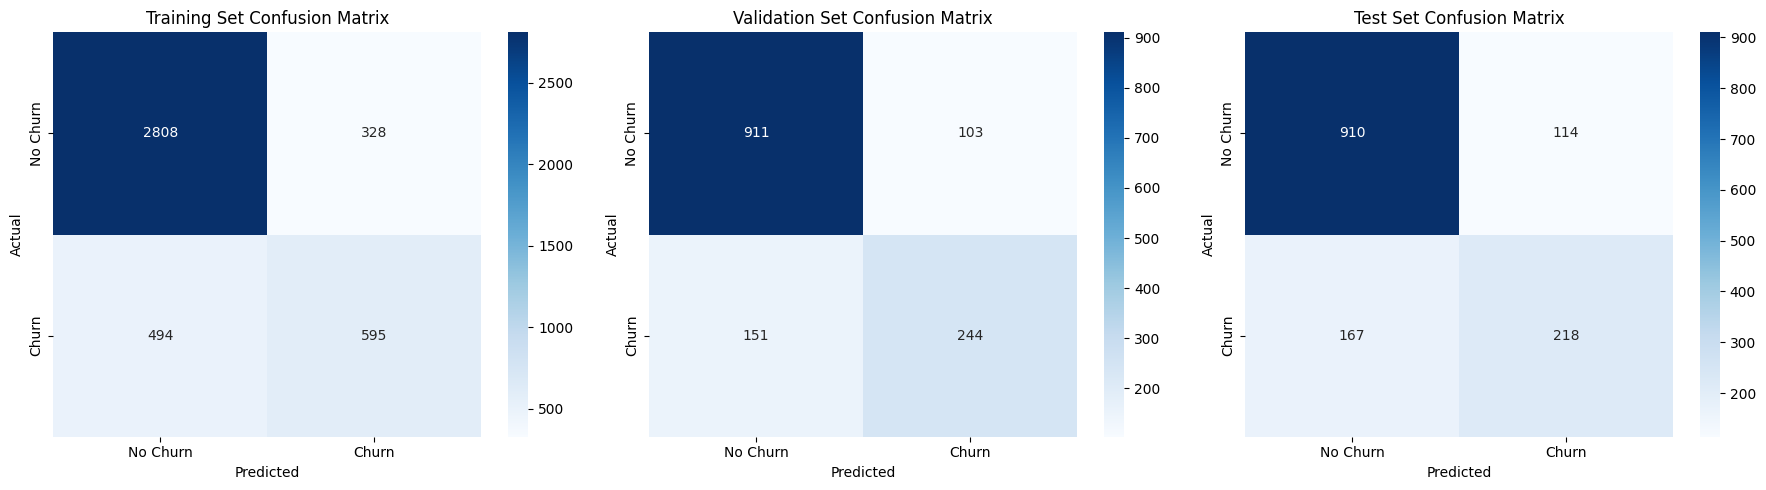

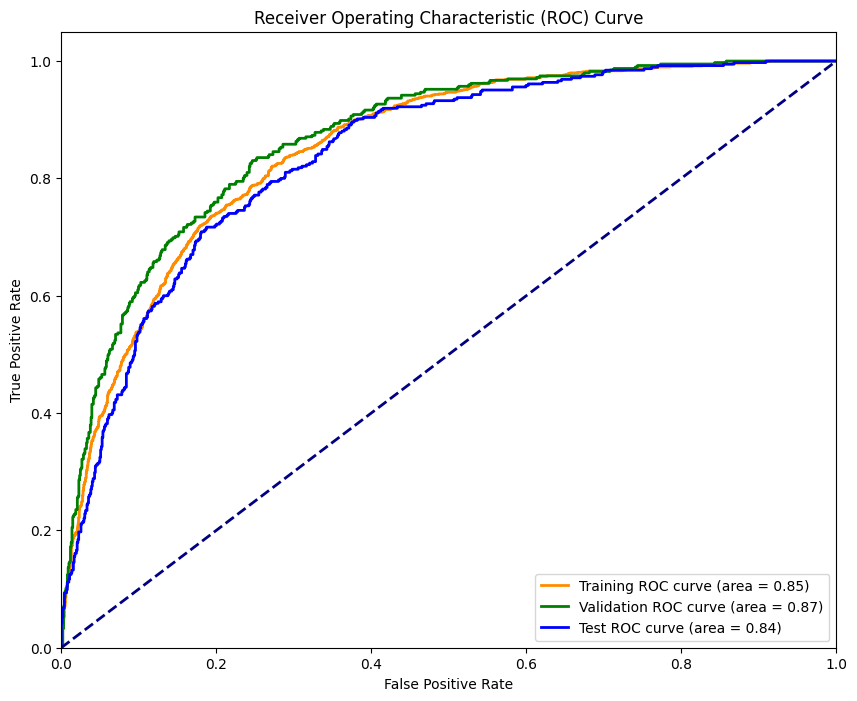

In [41]:
from sklearn.metrics import confusion_matrix, accuracy_score, roc_curve, auc, classification_report
import matplotlib.pyplot as plt
import seaborn as sns

# Make predictions on the training, validation, and test sets
y_train_pred = lda_model.predict(X_train)
y_val_pred = lda_model.predict(X_val)
y_test_pred = lda_model.predict(X_test)

# Calculate confusion matrices
conf_matrix_train = confusion_matrix(y_train, y_train_pred)
conf_matrix_val = confusion_matrix(y_val, y_val_pred)
conf_matrix_test = confusion_matrix(y_test, y_test_pred)

# Calculate accuracy scores
accuracy_train = accuracy_score(y_train, y_train_pred)
accuracy_val = accuracy_score(y_val, y_val_pred)
accuracy_test = accuracy_score(y_test, y_test_pred)

# Print classification reports (includes precision, recall, f1-score, and support)
print("Training Set Classification Report:")
print(classification_report(y_train, y_train_pred))

print("\nValidation Set Classification Report:")
print(classification_report(y_val, y_val_pred))

print("\nTest Set Classification Report:")
print(classification_report(y_test, y_test_pred))


# Plot confusion matrices
fig, axes = plt.subplots(1, 3, figsize=(18, 5))

sns.heatmap(conf_matrix_train, annot=True, fmt='d', cmap='Blues', ax=axes[0])
axes[0].set_title('Training Set Confusion Matrix')
axes[0].set_xlabel('Predicted')
axes[0].set_ylabel('Actual')
axes[0].set_xticklabels(['No Churn', 'Churn'])
axes[0].set_yticklabels(['No Churn', 'Churn'])


sns.heatmap(conf_matrix_val, annot=True, fmt='d', cmap='Blues', ax=axes[1])
axes[1].set_title('Validation Set Confusion Matrix')
axes[1].set_xlabel('Predicted')
axes[1].set_ylabel('Actual')
axes[1].set_xticklabels(['No Churn', 'Churn'])
axes[1].set_yticklabels(['No Churn', 'Churn'])


sns.heatmap(conf_matrix_test, annot=True, fmt='d', cmap='Blues', ax=axes[2])
axes[2].set_title('Test Set Confusion Matrix')
axes[2].set_xlabel('Predicted')
axes[2].set_ylabel('Actual')
axes[2].set_xticklabels(['No Churn', 'Churn'])
axes[2].set_yticklabels(['No Churn', 'Churn'])

plt.tight_layout()
plt.show()


# Calculate ROC curves and AUC
y_train_prob = lda_model.predict_proba(X_train)[:, 1]
y_val_prob = lda_model.predict_proba(X_val)[:, 1]
y_test_prob = lda_model.predict_proba(X_test)[:, 1]

fpr_train, tpr_train, thresholds_train = roc_curve(y_train, y_train_prob)
roc_auc_train = auc(fpr_train, tpr_train)

fpr_val, tpr_val, thresholds_val = roc_curve(y_val, y_val_prob)
roc_auc_val = auc(fpr_val, tpr_val)

fpr_test, tpr_test, thresholds_test = roc_curve(y_test, y_test_prob)
roc_auc_test = auc(fpr_test, tpr_test)

# Plot ROC curves
plt.figure(figsize=(10, 8))
plt.plot(fpr_train, tpr_train, color='darkorange', lw=2, label='Training ROC curve (area = %0.2f)' % roc_auc_train)
plt.plot(fpr_val, tpr_val, color='green', lw=2, label='Validation ROC curve (area = %0.2f)' % roc_auc_val)
plt.plot(fpr_test, tpr_test, color='blue', lw=2, label='Test ROC curve (area = %0.2f)' % roc_auc_test)
plt.plot([0, 1], [0, 1], color='navy', lw=2, linestyle='--')
plt.xlim([0.0, 1.0])
plt.ylim([0.0, 1.05])
plt.xlabel('False Positive Rate')
plt.ylabel('True Positive Rate')
plt.title('Receiver Operating Characteristic (ROC) Curve')
plt.legend(loc="lower right")
plt.show()

Key observations
1. Consistent model performance

Accuracy ranges from 80% to 82% across all three datasets. This suggests that the model generalizes reasonably well to unseen data, with no obvious indication of significant overfitting.

2. Better prediction of customers who do not churn

The model achieves an F1-score of 87% on the test set for Class 0, compared with 61% for Class 1. This indicates stronger performance in identifying customers who stay.

3. Churn prediction needs improvement

Test recall for Class 1 is 57%. This means the model identifies approximately 57% of actual customers who churn, while missing the remaining 43%.

4. Accuracy alone can be misleading

Since approximately 73% of customers do not churn, an accuracy of 80% does not necessarily mean the model is equally effective at identifying churners.

# @5. Comment on the model performance.  What did you observe in the results?

The model performed consistently across the training, validation, and test datasets, achieving accuracy of 81%, 82%, and 80%, respectively. This indicates that the model generalizes reasonably well to unseen data, with no significant signs of overfitting.

However, the model performed better at predicting customers who do not churn (Class 0), with an F1-score of 87% on the test set, compared to 61% for customers who churn (Class 1).

The recall for churn customers was 57%, meaning the model correctly identified only 57% of actual churn cases.

Overall, the model provides a reasonable baseline, but its ability to identify customers likely to churn needs improvement.

# @6. Build a Naïve Bayes model to predict churn using all predictors.

Since most of the data in this dataset is continuous, we will build the Gaussian version of the model which doesn't require binning.

In [42]:
from sklearn.naive_bayes import GaussianNB

# Initialize the Gaussian Naive Bayes model
gnb_model = GaussianNB()

# Train the model using the training data
gnb_model.fit(X_train, y_train)

print("Gaussian Naive Bayes model trained successfully.")

Gaussian Naive Bayes model trained successfully.


# @7. Check model performance by partition with total accuracy, precision, recall, F1 score, and AUC.

In [43]:
from sklearn.metrics import classification_report

# Make predictions on the training, validation, and test sets
y_train_pred_gnb = gnb_model.predict(X_train)
y_val_pred_gnb = gnb_model.predict(X_val)
y_test_pred_gnb = gnb_model.predict(X_test)

# Print the classification reports
print("Training Set Classification Report (Naive Bayes):")
print(classification_report(y_train, y_train_pred_gnb))

print("\nValidation Set Classification Report (Naive Bayes):")
print(classification_report(y_val, y_val_pred_gnb))

print("\nTest Set Classification Report (Naive Bayes):")
print(classification_report(y_test, y_test_pred_gnb))

Training Set Classification Report (Naive Bayes):
              precision    recall  f1-score   support

           0       0.90      0.75      0.82      3136
           1       0.52      0.77      0.62      1089

    accuracy                           0.76      4225
   macro avg       0.71      0.76      0.72      4225
weighted avg       0.80      0.76      0.77      4225


Validation Set Classification Report (Naive Bayes):
              precision    recall  f1-score   support

           0       0.91      0.76      0.83      1014
           1       0.57      0.80      0.66       395

    accuracy                           0.77      1409
   macro avg       0.74      0.78      0.75      1409
weighted avg       0.81      0.77      0.78      1409


Test Set Classification Report (Naive Bayes):
              precision    recall  f1-score   support

           0       0.90      0.74      0.81      1024
           1       0.53      0.77      0.63       385

    accuracy                    

Gaussian Naive Bayes model shows an interesting result: it is better at identifying customers who churn, but its overall accuracy is lower than previous model.

Cbservations
1. Consistent performance: Accuracy ranges from 75% to 77% across all three datasets, suggesting reasonable generalization without significant overfitting.

2. **Better churn identification**: Test recall for Class 1 is 77%, meaning the model identifies approximately 77% of actual customers who churn.

3. Lower precision: Test precision for Class 1 is 53%. This means that only about 53% of customers predicted to churn actually churn.

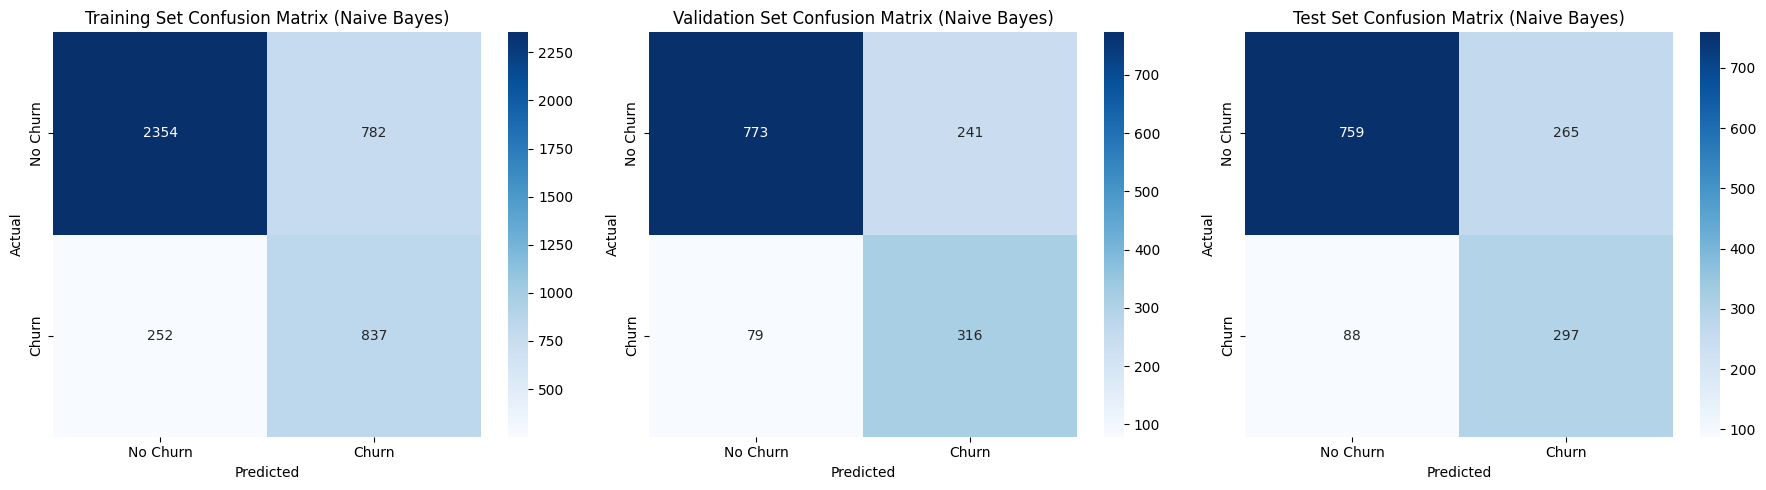

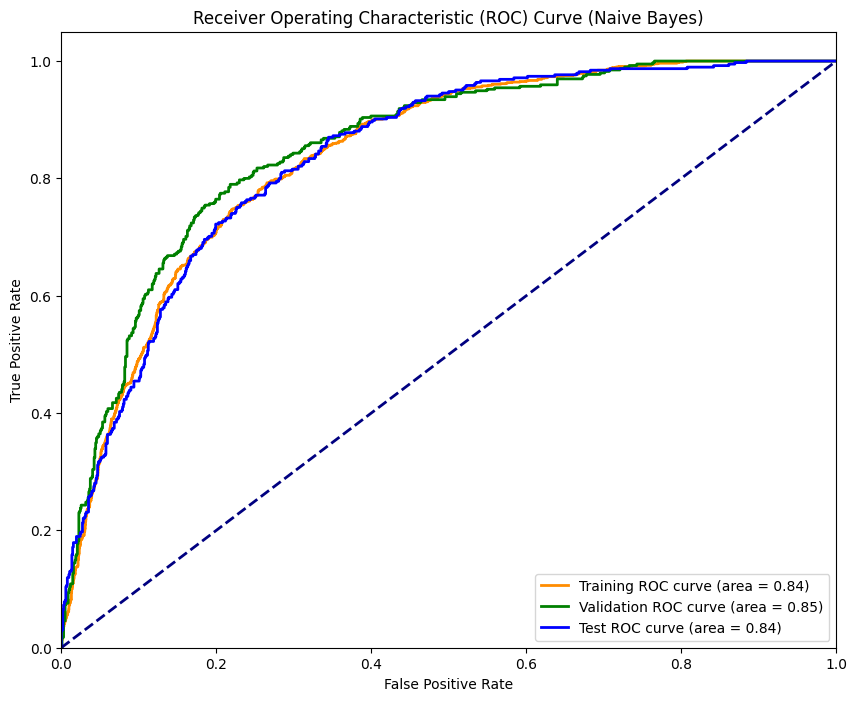

In [44]:
# Make predictions and get probabilities on the training, validation, and test sets
y_train_pred_gnb = gnb_model.predict(X_train)
y_val_pred_gnb = gnb_model.predict(X_val)
y_test_pred_gnb = gnb_model.predict(X_test)

y_train_prob_gnb = gnb_model.predict_proba(X_train)[:, 1]
y_val_prob_gnb = gnb_model.predict_proba(X_val)[:, 1]
y_test_prob_gnb = gnb_model.predict_proba(X_test)[:, 1]

# Calculate confusion matrices
conf_matrix_train_gnb = confusion_matrix(y_train, y_train_pred_gnb)
conf_matrix_val_gnb = confusion_matrix(y_val, y_val_pred_gnb)
conf_matrix_test_gnb = confusion_matrix(y_test, y_test_pred_gnb)

# Plot confusion matrices
fig, axes = plt.subplots(1, 3, figsize=(18, 5))

sns.heatmap(conf_matrix_train_gnb, annot=True, fmt='d', cmap='Blues', ax=axes[0])
axes[0].set_title('Training Set Confusion Matrix (Naive Bayes)')
axes[0].set_xlabel('Predicted')
axes[0].set_ylabel('Actual')
axes[0].set_xticklabels(['No Churn', 'Churn'])
axes[0].set_yticklabels(['No Churn', 'Churn'])


sns.heatmap(conf_matrix_val_gnb, annot=True, fmt='d', cmap='Blues', ax=axes[1])
axes[1].set_title('Validation Set Confusion Matrix (Naive Bayes)')
axes[1].set_xlabel('Predicted')
axes[1].set_ylabel('Actual')
axes[1].set_xticklabels(['No Churn', 'Churn'])
axes[1].set_yticklabels(['No Churn', 'Churn'])


sns.heatmap(conf_matrix_test_gnb, annot=True, fmt='d', cmap='Blues', ax=axes[2])
axes[2].set_title('Test Set Confusion Matrix (Naive Bayes)')
axes[2].set_xlabel('Predicted')
axes[2].set_ylabel('Actual')
axes[2].set_xticklabels(['No Churn', 'Churn'])
axes[2].set_yticklabels(['No Churn', 'Churn'])

plt.tight_layout()
plt.show()


# Calculate ROC curves and AUC
fpr_train_gnb, tpr_train_gnb, thresholds_train_gnb = roc_curve(y_train, y_train_prob_gnb)
roc_auc_train_gnb = auc(fpr_train_gnb, tpr_train_gnb)

fpr_val_gnb, tpr_val_gnb, thresholds_val_gnb = roc_curve(y_val, y_val_prob_gnb)
roc_auc_val_gnb = auc(fpr_val_gnb, tpr_val_gnb)

fpr_test_gnb, tpr_test_gnb, thresholds_test_gnb = roc_curve(y_test, y_test_prob_gnb)
roc_auc_test_gnb = auc(fpr_test_gnb, tpr_test_gnb)

# Plot ROC curves
plt.figure(figsize=(10, 8))
plt.plot(fpr_train_gnb, tpr_train_gnb, color='darkorange', lw=2, label='Training ROC curve (area = %0.2f)' % roc_auc_train_gnb)
plt.plot(fpr_val_gnb, tpr_val_gnb, color='green', lw=2, label='Validation ROC curve (area = %0.2f)' % roc_auc_val_gnb)
plt.plot(fpr_test_gnb, tpr_test_gnb, color='blue', lw=2, label='Test ROC curve (area = %0.2f)' % roc_auc_test_gnb)
plt.plot([0, 1], [0, 1], color='navy', lw=2, linestyle='--')
plt.xlim([0.0, 1.0])
plt.ylim([0.0, 1.05])
plt.xlabel('False Positive Rate')
plt.ylabel('True Positive Rate')
plt.title('Receiver Operating Characteristic (ROC) Curve (Naive Bayes)')
plt.legend(loc="lower right")
plt.show()

The confusion matrices provide additional insight into the performance of the Gaussian Naive Bayes model across the training, validation, and test datasets.

On the test dataset, the model correctly classified 759 customers as non-churners and 297 customers as churners. However, it incorrectly classified 265 non-churning customers as churners and missed 88 actual churners. This indicates that the model is relatively effective at identifying customers who are likely to churn, achieving approximately 77% recall for the churn class.

However, the relatively high number of false positives suggests that some retention efforts may be directed toward customers who would not have churned.

Overall, the confusion matrices show consistent model behavior across all three datasets.

# @8. Comment on the model performance.  What did you observe in the results?

The Gaussian Naive Bayes model achieved consistent accuracy across the training (76%), validation (77%), and test (75%) datasets, indicating that the model generalizes reasonably well without significant overfitting.

I observed that the model performs better at identifying customers who are likely to churn, achieving 77% recall for the churn class on the test dataset. However, its churn precision was only 53%, meaning that a considerable number of customers predicted to churn did not actually churn.

Overall, the model is useful for identifying potential churners, but its false-positive predictions could be a limitation when planning customer retention strategies.

# @9. Which model is better?  Justify your choice.

I would choose the **Discriminant analysis model** over Gaussian Naive Bayes if overall predictive performance is the primary consideration.

The discriminant analysis model achieved higher test accuracy (80% compared with 75%) and higher precision for the churn class (66% compared with 53%). This means it makes fewer incorrect churn predictions.

However, Gaussian Naive Bayes achieved higher recall for churn customers (77% compared with 57%), meaning it identifies a larger proportion of actual churners.

Overall, I prefer the discriminant analysis model because of its higher accuracy and precision. However, if the main business objective is to identify as many potential churners as possible, Gaussian Naive Bayes would be a better choice.